# Väderanalys och modellförsök

Syftet är att undersöka vädervariablernas samband med uthyrningen
och utvärdera en första modell med enbart väderdata.

## Datakälla

[Seoul Bike Sharing Demand – UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/560/seoul+bike+sharing+demand)

---

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

In [2]:
df = pd.read_csv(
    "../../data/SeoulBikeData.csv",
    encoding="cp1252"
)

df.head()

,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Date                       8760 non-null   str    
 1   Rented Bike Count          8760 non-null   int64  
 2   Hour                       8760 non-null   int64  
 3   Temperature(°C)            8760 non-null   float64
 4   Humidity(%)                8760 non-null   int64  
 5   Wind speed (m/s)           8760 non-null   float64
 6   Visibility (10m)           8760 non-null   int64  
 7   Dew point temperature(°C)  8760 non-null   float64
 8   Solar Radiation (MJ/m2)    8760 non-null   float64
 9   Rainfall(mm)               8760 non-null   float64
 10  Snowfall (cm)              8760 non-null   float64
 11  Seasons                    8760 non-null   str    
 12  Holiday                    8760 non-null   str    
 13  Functioning Day            8760 non-null   str    
dtypes: 

In [4]:
df.isna().sum()

Date                         0
Rented Bike Count            0
Hour                         0
Temperature(°C)              0
Humidity(%)                  0
Wind speed (m/s)             0
Visibility (10m)             0
Dew point temperature(°C)    0
Solar Radiation (MJ/m2)      0
Rainfall(mm)                 0
Snowfall (cm)                0
Seasons                      0
Holiday                      0
Functioning Day              0
dtype: int64

**Inga saknade värden**

---

In [5]:
df.duplicated().sum()

np.int64(0)

**Inga dubletter**

---

In [6]:
df["Rented Bike Count"].describe()

count    8760.000000
mean      704.602055
std       644.997468
min         0.000000
25%       191.000000
50%       504.500000
75%      1065.250000
max      3556.000000
Name: Rented Bike Count, dtype: float64

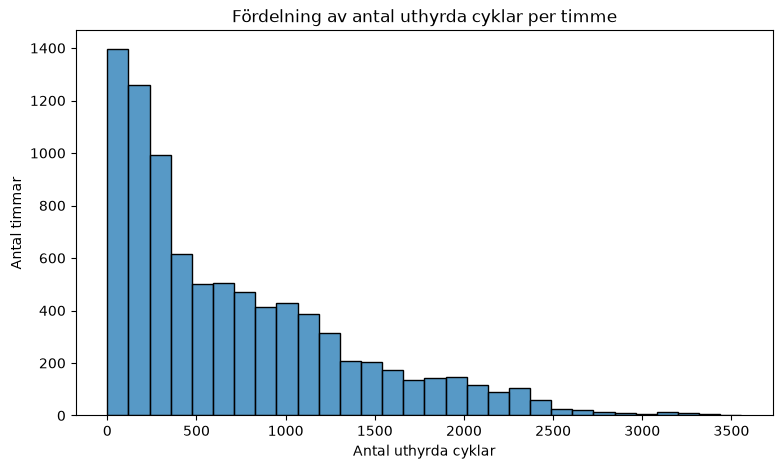

In [7]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="Rented Bike Count", bins=30)

plt.title("Fördelning av antal uthyrda cyklar per timme")
plt.xlabel("Antal uthyrda cyklar")
plt.ylabel("Antal timmar")
plt.show()

**Diagrammet visar att timmar med låg uthyrning är vanligare än timmar med mycket hög uthyrning.**

---

In [8]:
df.groupby("Functioning Day")["Rented Bike Count"].agg(
    ["count", "min", "mean", "max"]
)

,count,min,mean,max
Functioning Day,,,,
No,295,0,0.000000,0
Yes,8465,2,729.156999,3556


In [9]:
df_open = df[df["Functioning Day"] == "Yes"].copy()

Vi fokuserar på uthyrning under timmar då systemet är i drift. Därför exkluderar vi 295 stängda timmar med noll uthyrningar. Dessa nollor visar att uthyrning inte var möjlig, snarare än att efterfrågan saknades.

---

## 1. Temperaturdiagram

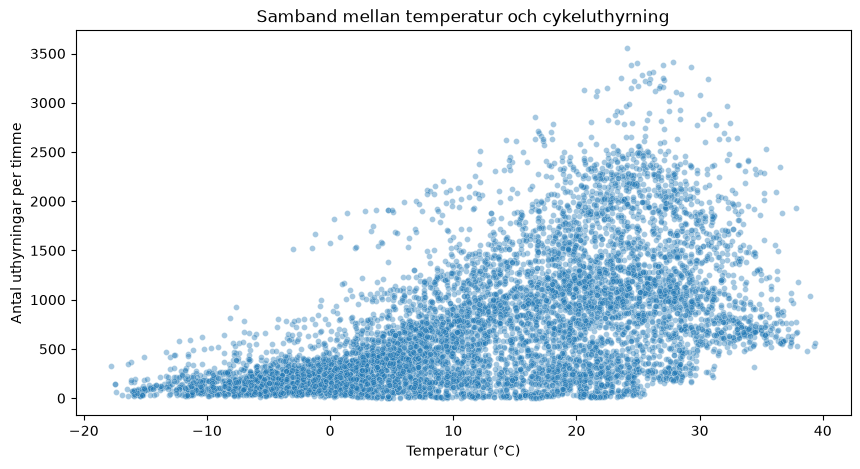

In [10]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_open,
    x="Temperature(°C)",
    y="Rented Bike Count",
    alpha=0.4,
    s=18,
)

plt.title("Samband mellan temperatur och cykeluthyrning")
plt.xlabel("Temperatur (°C)")
plt.ylabel("Antal uthyrningar per timme")
plt.show()

**Temperatur har ett positivt samband med cykeluthyrningen, men spridningen är stor vid samma temperatur. Det motiverar att testa temperatur som indata och undersöka om en kombination av väder och tidsinformation förbättrar förutsägelserna.**

---

## 2. Boxplot för regn

In [11]:
df_open["Rain category"] = (
    df_open["Rainfall(mm)"] > 0
).map({True: "Regn", False: "Inget regn"})

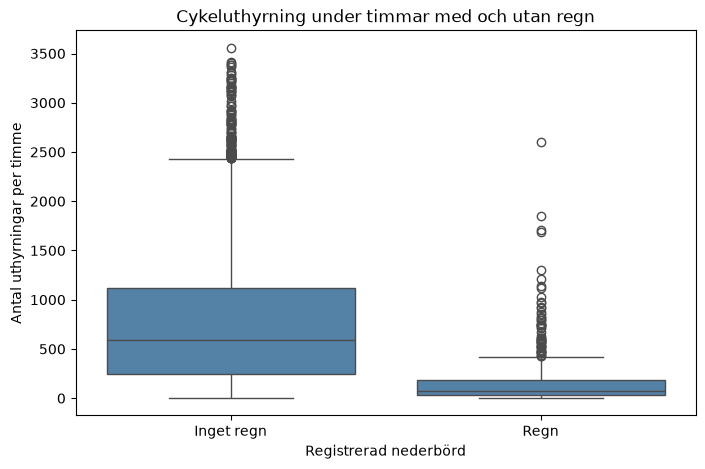

In [12]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_open,
    x="Rain category",
    y="Rented Bike Count",
    order=["Inget regn", "Regn"],
    color="steelblue",
)

plt.title("Cykeluthyrning under timmar med och utan regn")
plt.xlabel("Registrerad nederbörd")
plt.ylabel("Antal uthyrningar per timme")
plt.show()

**Uthyrningen har betydligt lägre median under regniga timmar än under timmar utan regn. Det motiverar att testa nederbörd som indata till modellen. Grupperna innehåller 516 respektive 7 949 timmar, och jämförelsen tar inte hänsyn till klockslag, temperatur eller årstid.**

In [13]:
df_open["Rain category"].value_counts()

Rain category
Inget regn    7949
Regn           516
Name: count, dtype: int64

---

## 3. Korrelationskarta

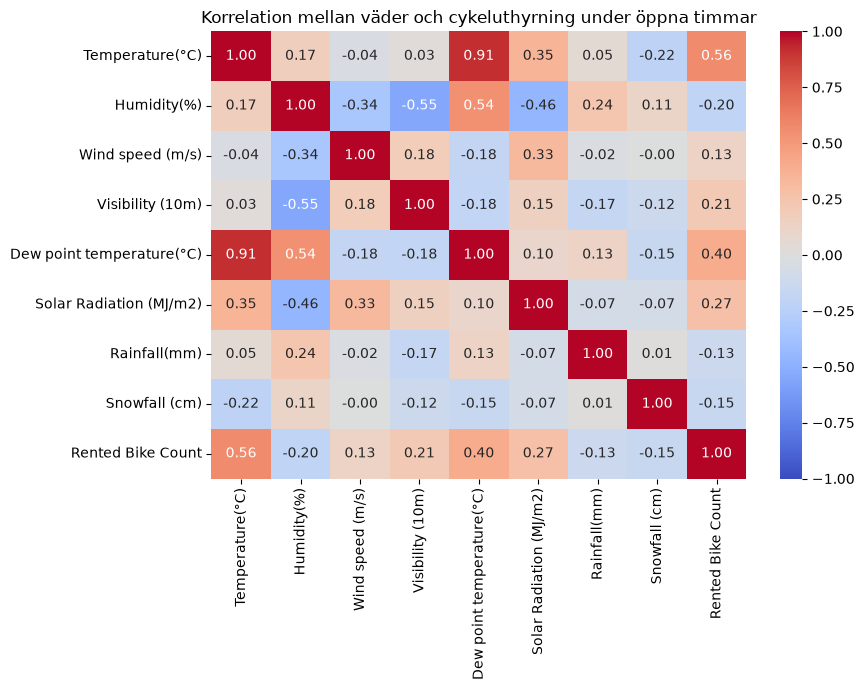

In [14]:
weather_columns = [
    "Temperature(°C)",
    "Humidity(%)",
    "Wind speed (m/s)",
    "Visibility (10m)",
    "Dew point temperature(°C)",
    "Solar Radiation (MJ/m2)",
    "Rainfall(mm)",
    "Snowfall (cm)",
    "Rented Bike Count"
]

weather_corr = df_open[weather_columns].corr()

plt.figure(figsize=(9, 7))

sns.heatmap(
    weather_corr,
    annot=True,
    fmt=".2f",
    vmin=-1,
    vmax=1,
    cmap="coolwarm"
)

plt.title("Korrelation mellan väder och cykeluthyrning under öppna timmar")
plt.tight_layout()
plt.show()

**Temperatur har starkast positivt linjärt samband med uthyrningen bland vädervariablerna. Temperatur och daggpunkt samvarierar starkt, vilket motiverar att undersöka om båda behövs i modellen. Regn behålls som kandidat trots låg linjär korrelation, eftersom boxploten visar tydligt lägre medianuthyrning under regniga timmar.**

---

## 4. Modellförsök med väderdata

Vi testar hur väl vädervariabler kan förutsäga uthyrningen under
öppna timmar. Försöket är preliminärt.

In [15]:
weather_features = [
    column for column in weather_columns
    if column != "Rented Bike Count"
]

X_weather = df_open[weather_features]
y_weather = df_open["Rented Bike Count"]

print("Indata:", X_weather.shape)
print("Målvariabel:", y_weather.shape)

Indata: (8465, 8)
Målvariabel: (8465,)


In [16]:
X_weather_train, X_weather_test, y_weather_train, y_weather_test = (
    train_test_split(
        X_weather,
        y_weather,
        test_size=0.2,
        random_state=42
    )
)

In [17]:
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_weather_train, y_weather_train)

baseline_predictions = baseline.predict(X_weather_test)

baseline_mae = mean_absolute_error(
    y_weather_test,
    baseline_predictions
)

print(f"Baslinjens MAE: {baseline_mae:.1f} uthyrningar per timme")

Baslinjens MAE: 509.7 uthyrningar per timme


In [18]:
weather_model = LinearRegression()
weather_model.fit(X_weather_train, y_weather_train)

weather_predictions = weather_model.predict(X_weather_test)

weather_mae = mean_absolute_error(
    y_weather_test,
    weather_predictions
)

print(f"Baslinjens MAE: {baseline_mae:.1f}")
print(f"Vädermodellens MAE: {weather_mae:.1f}")

Baslinjens MAE: 509.7
Vädermodellens MAE: 348.9


**Linjär regression med åtta vädervariabler gav MAE 348,9, jämfört med baslinjens 509,7. Väderinformationen minskade därmed det genomsnittliga absoluta felet med cirka 32 % på denna testuppdelning.**

---

In [19]:
weather_rmse = root_mean_squared_error(
    y_weather_test, weather_predictions
)

weather_r2 = r2_score(
    y_weather_test, weather_predictions
)

print(f"MAE: {weather_mae:.1f}")
print(f"RMSE: {weather_rmse:.1f}")
print(f"R²: {weather_r2:.3f}")

MAE: 348.9
RMSE: 470.6
R²: 0.436


Vädermodellen fick **MAE 348,9**, **RMSE 470,6** och **R² 0,436**. Modellen fångar en del av variationen i uthyrningen, men gör fortfarande betydande fel. RMSE är högre än MAE eftersom större missar får större tyngd. Resultaten gäller den nuvarande slumpmässiga testuppdelningen.

---

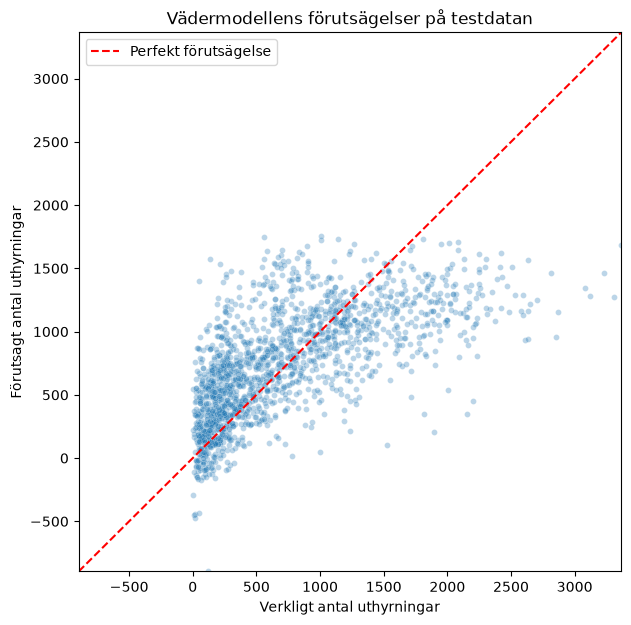

In [20]:
plt.figure(figsize=(7, 7))

sns.scatterplot(
    x=y_weather_test,
    y=weather_predictions,
    alpha=0.3,
    s=18
)

limits = [
    min(y_weather_test.min(), weather_predictions.min()),
    max(y_weather_test.max(), weather_predictions.max())
]

plt.plot(limits, limits, "--", color="red", label="Perfekt förutsägelse")
plt.xlim(limits)
plt.ylim(limits)
plt.xlabel("Verkligt antal uthyrningar")
plt.ylabel("Förutsagt antal uthyrningar")
plt.title("Vädermodellens förutsägelser på testdatan")
plt.legend()
plt.show()
